# ARTI 502 Assignment 1
## Training-Testing Neural Net with MNIST Dataset using PyTorch
**Year 2026 Term 1 — Group 5**

| Member Name | Academic ID |
|---|---|
| Abdulaziz Saqer BinRuqush | 2230007229 |
| Alwaleed Khalid alzahrani | 2230007172 |
| Ahmed Amer Alshehri | 2230002008 |

**Source repository:** https://github.com/az1zz/ARTI502-MNIST-Lab

We train on 50,000 images, tune on a separate 10,000-image validation split, and evaluate on the 10,000-image test split. All losses are averaged per image. Model selection uses the lowest validation loss, with validation accuracy as the tie-breaker.

## Task 1: Install and Load PyTorch
Dependencies: `python -m pip install torch torchvision matplotlib numpy`

In [1]:
import copy
import json
import random
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torch.utils.data import DataLoader, TensorDataset, random_split

SEED = 42
DEVICE = torch.device("cpu")
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Execution device:", DEVICE)
print("Random seed:", SEED)
print("Deterministic algorithms:", torch.are_deterministic_algorithms_enabled())

PyTorch version: 2.14.0+cpu
Torchvision version: 0.29.0+cpu
Execution device: cpu
Random seed: 42
Deterministic algorithms: True


## Task 2: Download and Load the Dataset
MNIST contains 60,000 development images and 10,000 test images. We reserve 10,000 development images for validation, leaving the 50,000 training images specified in the handout. Pixels are cached as float tensors in [0, 1], equivalent to `ToTensor`, to avoid repeating conversion during training.

In [2]:
raw_train = torchvision.datasets.MNIST("data", train=True, download=True)
raw_test = torchvision.datasets.MNIST("data", train=False, download=True)
train_split, val_split = random_split(
    raw_train, [50000, 10000], generator=torch.Generator().manual_seed(SEED)
)

def cached_dataset(raw, indices):
    images = raw.data[indices].unsqueeze(1).float().div(255)
    return TensorDataset(images, raw.targets[indices])

train_dataset = cached_dataset(raw_train, train_split.indices)
val_dataset = cached_dataset(raw_train, val_split.indices)
test_dataset = cached_dataset(raw_test, list(range(len(raw_test))))
BATCH_SIZE = 32

def make_train_loader():
    return DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                      generator=torch.Generator().manual_seed(SEED))

train_loader = make_train_loader()
train_eval_loader = DataLoader(train_dataset, batch_size=512, shuffle=False)
val_loader = DataLoader(val_dataset, batch_size=512, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
assert not set(train_split.indices).intersection(val_split.indices)
assert len(train_dataset) == 50000 and len(test_dataset) == 10000
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print("Training / test batches:", len(train_loader), "/", len(test_loader))
print("Train/validation overlap: 0 images")

100.0%
100.0%
100.0%
100.0%


Training images: 50000
Validation images: 10000
Test images: 10000
Training / test batches: 1563 / 313
Train/validation overlap: 0 images


## Task 3: Inspect the Dataset

In [3]:
images, labels = next(iter(train_loader))
print("Images tensor shape:", images.shape)
print("Labels tensor shape:", labels.shape)
print("Pixel range:", images.min().item(), "to", images.max().item())

Images tensor shape: torch.Size([32, 1, 28, 28])
Labels tensor shape: torch.Size([32])
Pixel range: 0.0 to 1.0


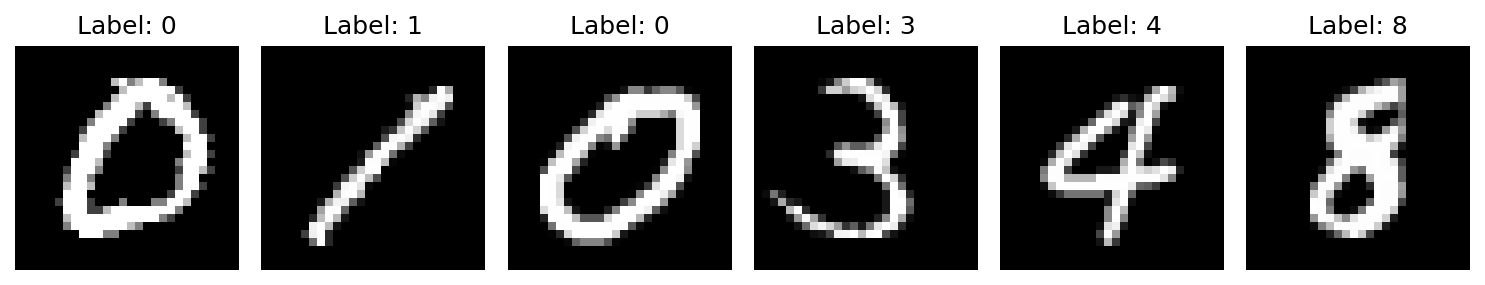

In [4]:
fig, axes = plt.subplots(1, 6, figsize=(10, 2.4))
for i, ax in enumerate(axes):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Task 4: Creating A Simple Network
The baseline uses one 128-neuron hidden layer, ReLU and ten output logits. The mini-batch dimension is preserved when flattening the images.

In [5]:
class SimpleNet(nn.Module):
    def __init__(self, input_size=784, hidden_size=128, num_classes=10):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        return self.fc2(self.relu(self.fc1(x)))

set_seed()
net = SimpleNet().to(DEVICE)
print(net)
print("Trainable parameters:", sum(p.numel() for p in net.parameters()))

SimpleNet(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Trainable parameters: 101770


In [6]:
sample_batch = torch.zeros(32, 1, 28, 28, device=DEVICE)
flattened = torch.flatten(sample_batch, start_dim=1)
output = net(sample_batch)
assert flattened.shape == (32, 784)
assert output.shape == (32, 10)
print("Input:", sample_batch.shape)
print("Flattened:", flattened.shape)
print("Output:", output.shape)
print("Architecture and flatten checks passed.")

Input: torch.Size([32, 1, 28, 28])
Flattened: torch.Size([32, 784])
Output: torch.Size([32, 10])
Architecture and flatten checks passed.


## Task 5: Training Function
CrossEntropyLoss receives raw logits. SGD uses configurable learning rate and momentum. The evaluation helper sums individual losses and divides by the total number of examples, including any smaller final batch. Epoch training and validation metrics are measured after each epoch using the same model state.

In [7]:
def evaluate(net, loader):
    was_training = net.training
    net.eval()
    criterion = nn.CrossEntropyLoss(reduction="sum")
    total_loss = 0.0
    correct = total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            logits = net(images)
            total_loss += criterion(logits, labels).item()
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    net.train(was_training)
    return {"loss": total_loss / total,
            "accuracy": 100.0 * correct / total,
            "correct": correct, "total": total}

In [8]:
def train(net, loader, epochs=5, lr=0.01, momentum=0.9, patience=None):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(net.parameters(), lr=lr, momentum=momentum)
    history = []
    batch_losses = []
    best_state = None
    best_key = (float("inf"), float("inf"))
    stale_epochs = 0
    best_epoch = 0
    for epoch in range(1, epochs + 1):
        net.train()
        for batch_idx, (images, labels) in enumerate(loader):
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            logits = net(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
            if batch_idx % 500 == 0 or batch_idx == len(loader) - 1:
                acc = 100 * (logits.argmax(1) == labels).float().mean().item()
                print(f"Epoch {epoch}/{epochs} Batch {batch_idx + 1}/{len(loader)} "
                      f"Loss {loss.item():.4f} Accuracy {acc:.2f}%")
        tr = evaluate(net, train_eval_loader)
        va = evaluate(net, val_loader)
        history.append({"epoch": epoch, "train_loss": tr["loss"],
                        "train_acc": tr["accuracy"], "val_loss": va["loss"],
                        "val_acc": va["accuracy"]})
        print(f"Epoch {epoch}: train loss={tr['loss']:.4f}, "
              f"accuracy={tr['accuracy']:.2f}%; val loss={va['loss']:.4f}, "
              f"accuracy={va['accuracy']:.2f}%")
        key = (va["loss"], -va["accuracy"])
        if key < best_key:
            best_key = key
            best_state = copy.deepcopy(net.state_dict())
            best_epoch = epoch
            stale_epochs = 0
        else:
            stale_epochs += 1
        if patience is not None and stale_epochs >= patience:
            print(f"Early stopping after epoch {epoch}.")
            break
    net.load_state_dict(best_state)
    print(f"Restored minimum-validation-loss checkpoint: epoch {best_epoch}")
    return history, batch_losses, best_epoch

## Task 6: Training Network
The baseline and each search trial use the same seed, shuffled-batch sequence and five-epoch budget. Each run restores its minimum-validation-loss checkpoint. Test data is never passed to the training function.

In [9]:
set_seed()
net = SimpleNet().to(DEVICE)
baseline_history, baseline_batch_losses, baseline_epoch = train(
    net, make_train_loader(), epochs=5, lr=0.01, momentum=0.9
)
baseline_val = evaluate(net, val_loader)
print("Baseline selected epoch:", baseline_epoch)
print("Baseline validation metrics:", baseline_val)

Epoch 1/5 Batch 1/1563 Loss 2.2726 Accuracy 15.62%
Epoch 1/5 Batch 501/1563 Loss 0.2244 Accuracy 96.88%
Epoch 1/5 Batch 1001/1563 Loss 0.5067 Accuracy 84.38%
Epoch 1/5 Batch 1501/1563 Loss 0.1514 Accuracy 93.75%
Epoch 1/5 Batch 1563/1563 Loss 0.3341 Accuracy 87.50%
Epoch 1: train loss=0.2050, accuracy=94.13%; val loss=0.2260, accuracy=93.59%
Epoch 2/5 Batch 1/1563 Loss 0.2994 Accuracy 90.62%
Epoch 2/5 Batch 501/1563 Loss 0.0484 Accuracy 100.00%
Epoch 2/5 Batch 1001/1563 Loss 0.9093 Accuracy 81.25%
Epoch 2/5 Batch 1501/1563 Loss 0.1618 Accuracy 96.88%
Epoch 2/5 Batch 1563/1563 Loss 0.0257 Accuracy 100.00%
Epoch 2: train loss=0.1322, accuracy=96.28%; val loss=0.1622, accuracy=95.42%
Epoch 3/5 Batch 1/1563 Loss 0.1639 Accuracy 90.62%
Epoch 3/5 Batch 501/1563 Loss 0.0641 Accuracy 100.00%
Epoch 3/5 Batch 1001/1563 Loss 0.1546 Accuracy 90.62%
Epoch 3/5 Batch 1501/1563 Loss 0.0158 Accuracy 100.00%
Epoch 3/5 Batch 1563/1563 Loss 0.2997 Accuracy 87.50%
Epoch 3: train loss=0.1019, accuracy=97.15

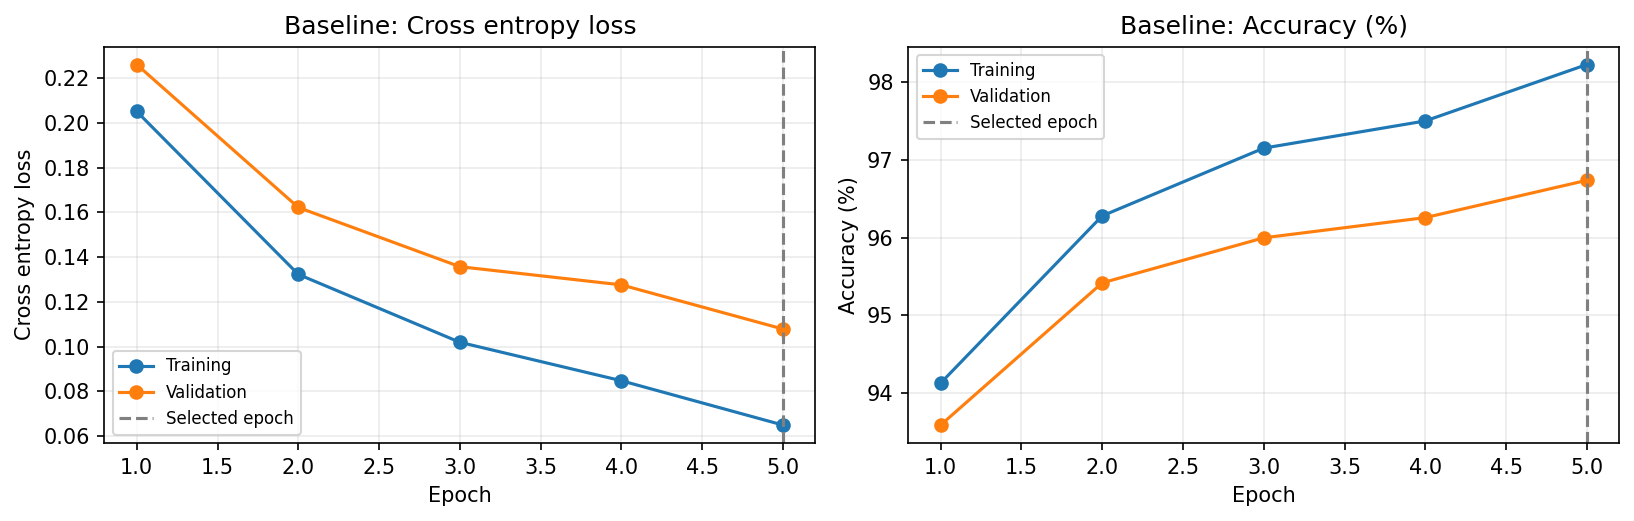

In [10]:
def plot_history(history, title, selected_epoch):
    epochs = [r["epoch"] for r in history]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    for ax, metric, ylabel in [(axes[0], "loss", "Cross entropy loss"),
                               (axes[1], "acc", "Accuracy (%)")]:
        ax.plot(epochs, [r[f"train_{metric}"] for r in history], "o-", label="Training")
        ax.plot(epochs, [r[f"val_{metric}"] for r in history], "o-", label="Validation")
        ax.axvline(selected_epoch, color="gray", linestyle="--", label="Selected epoch")
        ax.set(xlabel="Epoch", ylabel=ylabel, title=f"{title}: {ylabel}")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

plot_history(baseline_history, "Baseline", baseline_epoch)

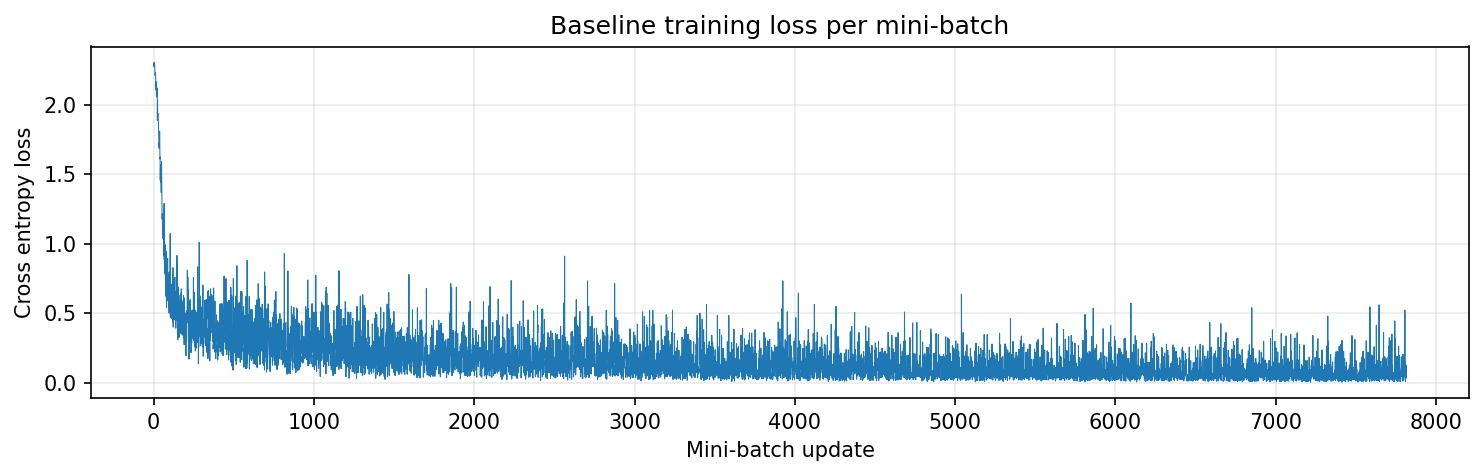

In [11]:
plt.figure(figsize=(10, 3.3))
plt.plot(range(1, len(baseline_batch_losses) + 1), baseline_batch_losses, linewidth=0.5)
plt.xlabel("Mini-batch update")
plt.ylabel("Cross entropy loss")
plt.title("Baseline training loss per mini-batch")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Task 7: Testing Network
The selected baseline checkpoint is evaluated once on all 10,000 test images. Prediction examples are displayed with their true labels. This baseline test result is not used to choose later configurations.

In [12]:
def test(net, loader, name):
    metrics = evaluate(net, loader)
    print(f"{name}: test loss={metrics['loss']:.6f}, "
          f"test accuracy={metrics['accuracy']:.2f}% "
          f"({metrics['correct']}/{metrics['total']} correct)")
    return metrics

baseline_test = test(net, test_loader, "Baseline")

Baseline: test loss=0.094388, test accuracy=97.29% (9729/10000 correct)


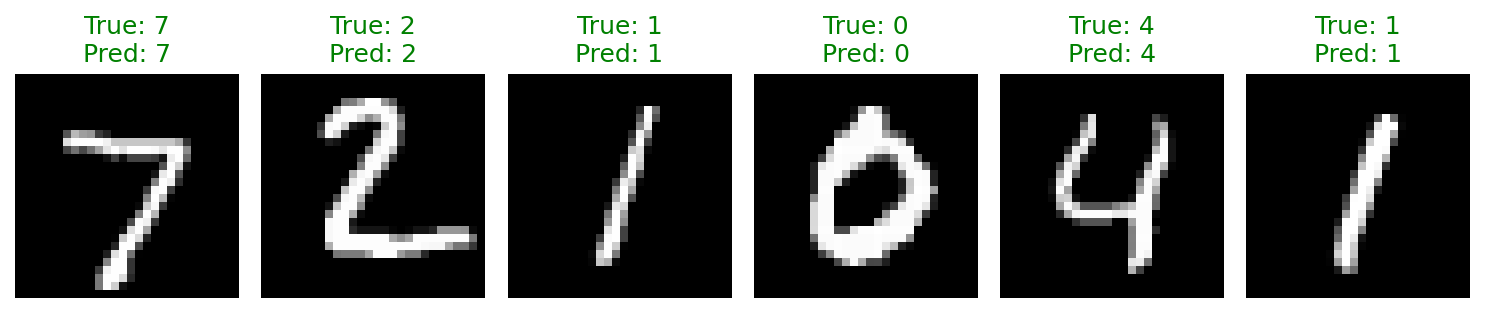

In [13]:
test_images, test_labels = next(iter(test_loader))
net.eval()
with torch.no_grad():
    predictions = net(test_images.to(DEVICE)).argmax(dim=1).cpu()
fig, axes = plt.subplots(1, 6, figsize=(10, 2.5))
for i, ax in enumerate(axes):
    ax.imshow(test_images[i].squeeze(), cmap="gray")
    color = "green" if predictions[i] == test_labels[i] else "red"
    ax.set_title(f"True: {test_labels[i]}\nPred: {predictions[i]}", color=color)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Task 8: Tuning the Parameters and Model Architecture
We compare learning rate and momentum, then architecture, using validation data only. Each candidate trains for five epochs and is scored at its minimum-validation-loss checkpoint. Model selection minimizes validation loss; accuracy is the tie-breaker. Both the lowest-loss and highest-accuracy results are reported explicitly.

In [14]:
class ConfigurableNet(nn.Module):
    def __init__(self, hidden_sizes=(128,)):
        super().__init__()
        layers = []
        in_features = 784
        for width in hidden_sizes:
            layers.extend([nn.Linear(in_features, width), nn.ReLU()])
            in_features = width
        layers.append(nn.Linear(in_features, 10))
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(torch.flatten(x, start_dim=1))

def selection_key(row):
    return (row["val_loss"], -row["val_acc"])

In [15]:
optimizer_configs = [(0.01, 0.9), (0.1, 0.9), (0.01, 0.5), (0.001, 0.9)]
optimizer_results = []
for lr, momentum in optimizer_configs:
    print(f"\nLearning rate={lr}, momentum={momentum}")
    set_seed()
    trial = SimpleNet().to(DEVICE)
    _, _, epoch = train(trial, make_train_loader(), epochs=5, lr=lr, momentum=momentum)
    metrics = evaluate(trial, val_loader)
    optimizer_results.append({"lr": lr, "momentum": momentum, "epoch": epoch,
                              "val_loss": metrics["loss"], "val_acc": metrics["accuracy"]})
best_optimizer = min(optimizer_results, key=selection_key)
print("\nOptimizer results:")
for row in optimizer_results:
    print(row)
print("Selected optimizer:", best_optimizer)


Learning rate=0.01, momentum=0.9
Epoch 1/5 Batch 1/1563 Loss 2.2726 Accuracy 15.62%
Epoch 1/5 Batch 501/1563 Loss 0.2244 Accuracy 96.88%
Epoch 1/5 Batch 1001/1563 Loss 0.5067 Accuracy 84.38%
Epoch 1/5 Batch 1501/1563 Loss 0.1514 Accuracy 93.75%
Epoch 1/5 Batch 1563/1563 Loss 0.3341 Accuracy 87.50%
Epoch 1: train loss=0.2050, accuracy=94.13%; val loss=0.2260, accuracy=93.59%
Epoch 2/5 Batch 1/1563 Loss 0.2994 Accuracy 90.62%
Epoch 2/5 Batch 501/1563 Loss 0.0484 Accuracy 100.00%
Epoch 2/5 Batch 1001/1563 Loss 0.9093 Accuracy 81.25%
Epoch 2/5 Batch 1501/1563 Loss 0.1618 Accuracy 96.88%
Epoch 2/5 Batch 1563/1563 Loss 0.0257 Accuracy 100.00%
Epoch 2: train loss=0.1322, accuracy=96.28%; val loss=0.1622, accuracy=95.42%
Epoch 3/5 Batch 1/1563 Loss 0.1639 Accuracy 90.62%
Epoch 3/5 Batch 501/1563 Loss 0.0641 Accuracy 100.00%
Epoch 3/5 Batch 1001/1563 Loss 0.1546 Accuracy 90.62%
Epoch 3/5 Batch 1501/1563 Loss 0.0158 Accuracy 100.00%
Epoch 3/5 Batch 1563/1563 Loss 0.2997 Accuracy 87.50%
Epoch 3:

In [16]:
architectures = [(64,), (128,), (256,), (128, 64), (256, 128, 64)]
architecture_results = []
for hidden_sizes in architectures:
    print(f"\nHidden layers={hidden_sizes}")
    set_seed()
    trial = ConfigurableNet(hidden_sizes).to(DEVICE)
    _, _, epoch = train(trial, make_train_loader(), epochs=5,
                        lr=best_optimizer["lr"], momentum=best_optimizer["momentum"])
    metrics = evaluate(trial, val_loader)
    architecture_results.append({"hidden_sizes": hidden_sizes, "epoch": epoch,
        "parameters": sum(p.numel() for p in trial.parameters()),
        "val_loss": metrics["loss"], "val_acc": metrics["accuracy"]})
best_architecture = min(architecture_results, key=selection_key)
print("\nArchitecture results:")
for row in architecture_results:
    print(row)
print("Selected architecture:", best_architecture)


Hidden layers=(64,)
Epoch 1/5 Batch 1/1563 Loss 2.2726 Accuracy 21.88%
Epoch 1/5 Batch 501/1563 Loss 0.2133 Accuracy 96.88%
Epoch 1/5 Batch 1001/1563 Loss 0.5024 Accuracy 84.38%
Epoch 1/5 Batch 1501/1563 Loss 0.1564 Accuracy 93.75%
Epoch 1/5 Batch 1563/1563 Loss 0.3682 Accuracy 87.50%
Epoch 1: train loss=0.2164, accuracy=93.72%; val loss=0.2394, accuracy=93.09%
Epoch 2/5 Batch 1/1563 Loss 0.3811 Accuracy 93.75%
Epoch 2/5 Batch 501/1563 Loss 0.0688 Accuracy 100.00%
Epoch 2/5 Batch 1001/1563 Loss 0.8863 Accuracy 81.25%
Epoch 2/5 Batch 1501/1563 Loss 0.1521 Accuracy 93.75%
Epoch 2/5 Batch 1563/1563 Loss 0.0315 Accuracy 100.00%
Epoch 2: train loss=0.1459, accuracy=95.95%; val loss=0.1792, accuracy=94.75%
Epoch 3/5 Batch 1/1563 Loss 0.1524 Accuracy 90.62%
Epoch 3/5 Batch 501/1563 Loss 0.0628 Accuracy 100.00%
Epoch 3/5 Batch 1001/1563 Loss 0.2185 Accuracy 90.62%
Epoch 3/5 Batch 1501/1563 Loss 0.0152 Accuracy 100.00%
Epoch 3/5 Batch 1563/1563 Loss 0.3046 Accuracy 87.50%
Epoch 3: train loss=0

Optimizer lowest validation loss: {'lr': 0.01, 'momentum': 0.9, 'epoch': 5, 'val_loss': 0.10780862369537353, 'val_acc': 96.74}
Optimizer highest validation accuracy: {'lr': 0.01, 'momentum': 0.9, 'epoch': 5, 'val_loss': 0.10780862369537353, 'val_acc': 96.74}
Architecture lowest validation loss: {'hidden_sizes': (256, 128, 64), 'epoch': 5, 'parameters': 242762, 'val_loss': 0.09912152366638184, 'val_acc': 96.96}
Architecture highest validation accuracy: {'hidden_sizes': (256,), 'epoch': 5, 'parameters': 203530, 'val_loss': 0.1003319088935852, 'val_acc': 97.07}


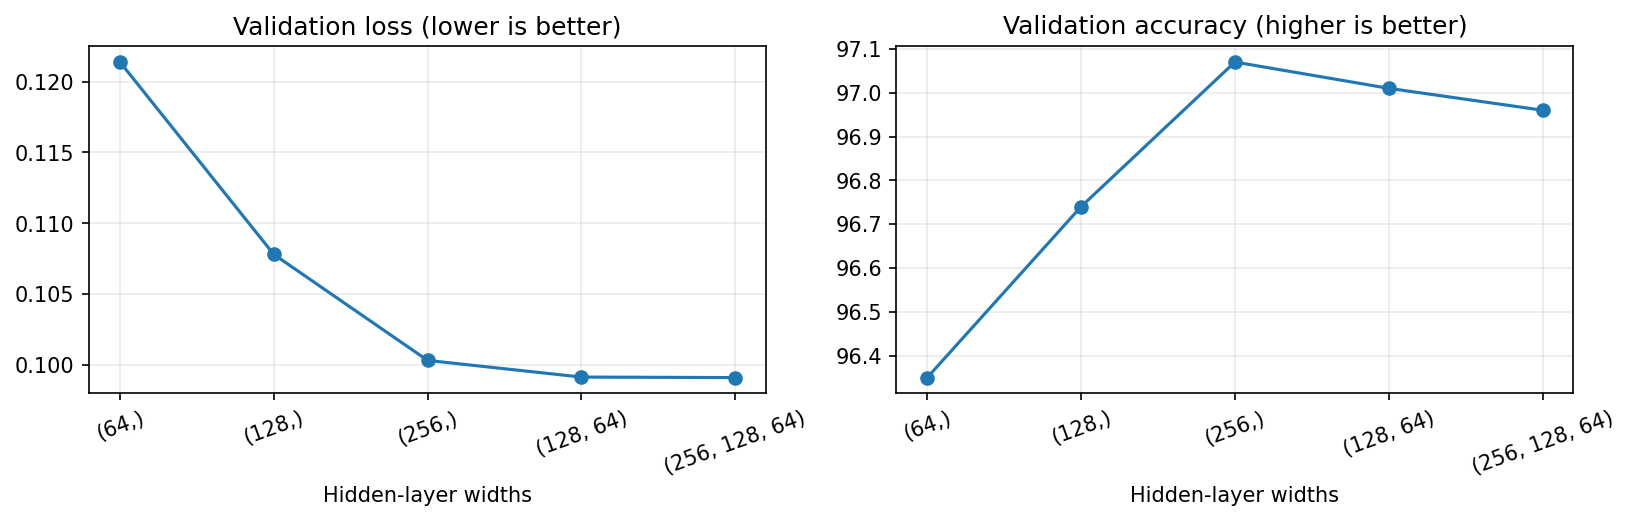

In [17]:
for name, rows in [("Optimizer", optimizer_results), ("Architecture", architecture_results)]:
    lowest_loss = min(rows, key=selection_key)
    highest_accuracy = max(rows, key=lambda r: (r["val_acc"], -r["val_loss"]))
    print(f"{name} lowest validation loss:", lowest_loss)
    print(f"{name} highest validation accuracy:", highest_accuracy)

labels = [str(r["hidden_sizes"]) for r in architecture_results]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, key, title in [(axes[0], "val_loss", "Validation loss (lower is better)"),
                        (axes[1], "val_acc", "Validation accuracy (higher is better)")]:
    values = [r[key] for r in architecture_results]
    ax.plot(range(len(labels)), values, "o-")
    ax.set_xticks(range(len(labels)), labels, rotation=20)
    ax.set(xlabel="Hidden-layer widths", title=title)
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [18]:
set_seed()
final_net = ConfigurableNet(best_architecture["hidden_sizes"]).to(DEVICE)
final_history, final_batch_losses, final_epoch = train(
    final_net, make_train_loader(), epochs=25,
    lr=best_optimizer["lr"], momentum=best_optimizer["momentum"], patience=5
)
final_train = evaluate(final_net, train_eval_loader)
final_val = evaluate(final_net, val_loader)
assert final_val["loss"] <= min(r["val_loss"] for r in final_history) + 1e-6
print("Final selected epoch:", final_epoch)
print("Final training metrics:", final_train)
print("Final validation metrics:", final_val)

Epoch 1/25 Batch 1/1563 Loss 2.2730 Accuracy 12.50%
Epoch 1/25 Batch 501/1563 Loss 0.3175 Accuracy 93.75%
Epoch 1/25 Batch 1001/1563 Loss 0.4725 Accuracy 87.50%
Epoch 1/25 Batch 1501/1563 Loss 0.2350 Accuracy 90.62%
Epoch 1/25 Batch 1563/1563 Loss 0.3183 Accuracy 87.50%
Epoch 1: train loss=0.1653, accuracy=94.79%; val loss=0.1930, accuracy=94.19%
Epoch 2/25 Batch 1/1563 Loss 0.1588 Accuracy 96.88%
Epoch 2/25 Batch 501/1563 Loss 0.0403 Accuracy 100.00%
Epoch 2/25 Batch 1001/1563 Loss 0.6905 Accuracy 84.38%
Epoch 2/25 Batch 1501/1563 Loss 0.1466 Accuracy 93.75%
Epoch 2/25 Batch 1563/1563 Loss 0.0094 Accuracy 100.00%
Epoch 2: train loss=0.0863, accuracy=97.44%; val loss=0.1217, accuracy=96.32%
Epoch 3/25 Batch 1/1563 Loss 0.1638 Accuracy 90.62%
Epoch 3/25 Batch 501/1563 Loss 0.0379 Accuracy 100.00%
Epoch 3/25 Batch 1001/1563 Loss 0.2337 Accuracy 90.62%
Epoch 3/25 Batch 1501/1563 Loss 0.0212 Accuracy 100.00%
Epoch 3/25 Batch 1563/1563 Loss 0.4266 Accuracy 93.75%
Epoch 3: train loss=0.0657,

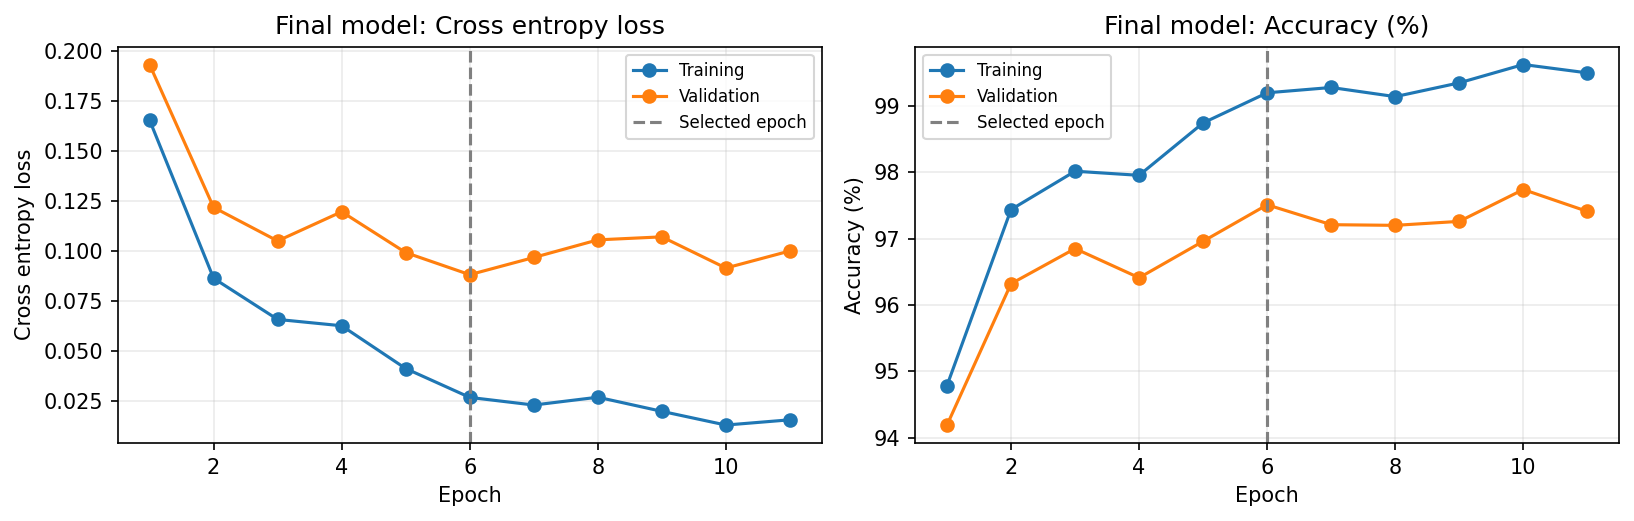

In [19]:
plot_history(final_history, "Final model", final_epoch)

In [20]:
final_test = test(final_net, test_loader, "Final model")
print("Selected learning rate:", best_optimizer["lr"])
print("Selected momentum:", best_optimizer["momentum"])
print("Selected hidden layers:", best_architecture["hidden_sizes"])
print("Selected epoch:", final_epoch)
print(f"Accuracy improvement: {final_test['accuracy'] - baseline_test['accuracy']:.2f} percentage points")
print(f"Test loss reduction: {baseline_test['loss'] - final_test['loss']:.6f}")

Final model: test loss=0.079208, test accuracy=97.82% (9782/10000 correct)
Selected learning rate: 0.01
Selected momentum: 0.9
Selected hidden layers: (256, 128, 64)
Selected epoch: 6
Accuracy improvement: 0.53 percentage points
Test loss reduction: 0.015180


## Task 9: Save Your Source Code
Repository: https://github.com/az1zz/ARTI502-MNIST-Lab

The executed notebook is saved as **Assigment-1_DL.ipynb**. The code below also saves the selected checkpoint, exact experiment results and a Python source export.

In [21]:
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)
results = {"seed": SEED, "batch_size": BATCH_SIZE,
    "split_sizes": {"train": 50000, "validation": 10000, "test": 10000},
    "baseline_epoch": baseline_epoch, "baseline_history": baseline_history,
    "baseline_val": baseline_val, "baseline_test": baseline_test,
    "optimizer_results": optimizer_results, "architecture_results": architecture_results,
    "best_optimizer": best_optimizer, "best_architecture": best_architecture,
    "final_epoch": final_epoch, "final_history": final_history,
    "final_train": final_train, "final_val": final_val, "final_test": final_test}
(ARTIFACTS / "results.json").write_text(json.dumps(results, indent=2))
torch.save({"model_state_dict": final_net.state_dict(),
            "hidden_sizes": best_architecture["hidden_sizes"],
            "selected_epoch": final_epoch}, ARTIFACTS / "mnist_model.pt")
source_path = Path("Assigment-1_DL.ipynb")
if source_path.exists():
    notebook = json.loads(source_path.read_text())
    source = "\n\n".join("".join(c["source"]) for c in notebook["cells"] if c["cell_type"] == "code")
    (ARTIFACTS / "Assigment-1_DL.py").write_text(source)
print("Saved exact results: artifacts/results.json")
print("Saved model checkpoint: artifacts/mnist_model.pt")
print("Repository: https://github.com/az1zz/ARTI502-MNIST-Lab")

Saved exact results: artifacts/results.json
Saved model checkpoint: artifacts/mnist_model.pt
Repository: https://github.com/az1zz/ARTI502-MNIST-Lab
